# Q1C | Analyze Relationships Between Attributes

> *Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.*

This notebook answers the question in three parts:

1. **PCC setup:** confirms PCC applies to every attribute and defines the strength thresholds.
2. **Attributes vs label:** PCC between each attribute and `Life Ladder`, with a scatter plot for each.
3. **Attributes vs attributes:** the full PCC matrix, the most and least correlated pairs, and scatter plots for the strongest pairs.

A **Summary** at the end lists the key relationships with their PCC values.

### Imports

In [1]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pandas.plotting import scatter_matrix

from Q1_OLD_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.rank_feature_pairs_by_combined_corr import rank_feature_pairs_by_combined_corr

### Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

---

> **IMPORTANT**
>
> This notebook uses only the `train` dataset, so no analysis is influenced by the test data (`data snooping`). Every correlation below is computed on the training rows only.

---

# 1. PCC Setup

In [3]:
print(train_df.dtypes.value_counts().to_string())
print(f"Distinct values per column: min {train_df.nunique().min()} ({train_df.nunique().idxmin()}), max {train_df.nunique().max()}")
print(f"Label: {TARGET}")

float64    9
Distinct values per column: min 354 (Negative affect), max 1302
Label: Life Ladder


All 9 columns are numeric with at least 354 distinct values, so all are continuous, including the label `Life Ladder`. PCC measures linear association between continuous variables, so it applies to every pair here. No categorical or ID columns need to be excluded.

`pandas.corr()` uses the rows where both attributes are present (pairwise deletion), so each r may use a slightly different set of rows.

**Strength thresholds used in this notebook (by |r|):**

| Strength | abs(r) |
|---|---|
| strong | ≥ 0.7 |
| moderate | 0.4 to < 0.7 |
| weak | 0.2 to < 0.4 |
| very weak | < 0.2 |

A positive r means the two attributes tend to increase together. A negative r means one tends to decrease as the other increases. Correlation describes association only, not cause.

In [4]:
def pcc_strength(r):
	a = abs(r)
	if a >= 0.7:
		return 'strong'
	if a >= 0.4:
		return 'moderate'
	if a >= 0.2:
		return 'weak'
	return 'very weak'


correlation_matrix = train_df.corr()

# 2. Attributes vs Label

The table ranks every attribute by the size of its PCC with `Life Ladder`. Spearman's rho is shown alongside as a supplement: it measures rank (monotonic) association, so a large gap between the two flags a relationship that is not well described by a straight line.

In [5]:
target_corr = pd.DataFrame({
	'Pearson r': correlation_matrix[TARGET].drop(TARGET),
	'Spearman rho': train_df.corr(method='spearman')[TARGET].drop(TARGET),
})
target_corr['direction'] = np.where(target_corr['Pearson r'] > 0, 'positive', 'negative')
target_corr['strength'] = target_corr['Pearson r'].map(pcc_strength)
target_corr = target_corr.sort_values('Pearson r', key=abs, ascending=False)
target_corr.round(3)

,Pearson r,Spearman rho,direction,strength
Log GDP per capita,0.787,0.799,positive,strong
Healthy life expectancy at birth,0.751,0.788,positive,strong
Social support,0.704,0.747,positive,strong
Positive affect,0.535,0.536,positive,moderate
Freedom to make life choices,0.530,0.538,positive,moderate
Perceptions of corruption,-0.428,-0.319,negative,moderate
Negative affect,-0.302,-0.260,negative,weak
Generosity,0.195,0.170,positive,very weak


- **Strong:** Log GDP per capita (0.787), Healthy life expectancy at birth (0.751), and Social support (0.704) have the strongest positive correlation with Life Ladder.
- **Moderate:** Positive affect (0.535) and Freedom to make life choices (0.530) are positive. Perceptions of corruption (-0.428) is negative.
- **Weak or very weak:** Negative affect (-0.302) is weak and negative. Generosity (0.195) is very weak and the weakest overall.
- Spearman and Pearson agree within 0.05 for every attribute except Perceptions of corruption (-0.319 vs -0.428), where the linear and rank measures differ the most.

## Scatter Plots vs Label

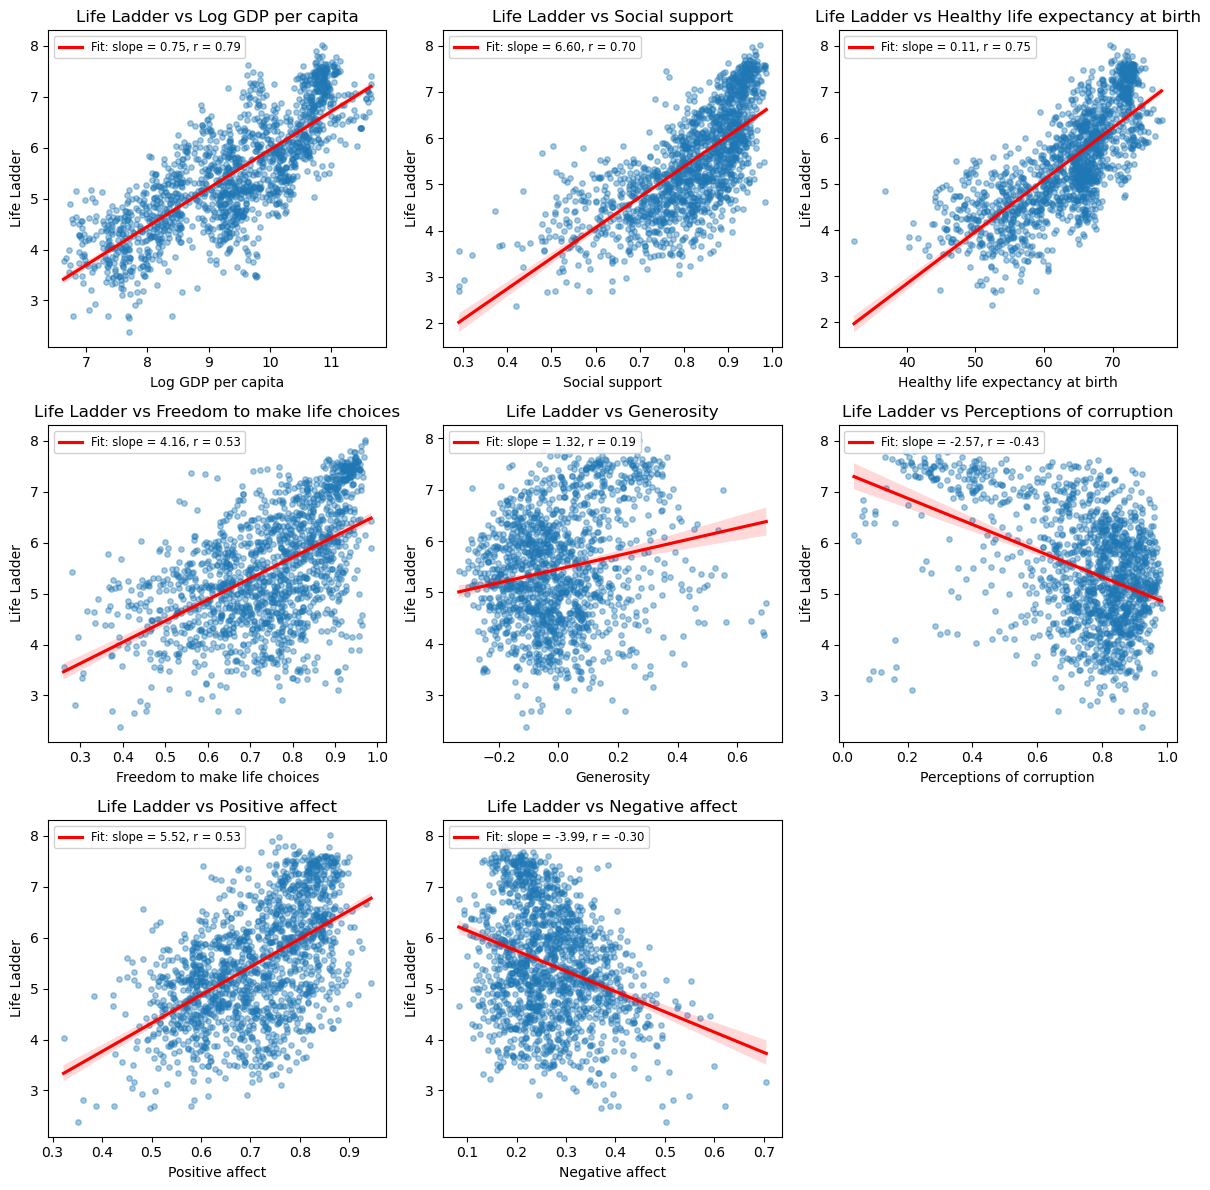

In [6]:
columns = train_df.columns.drop(TARGET)
ncols = 3
nrows = math.ceil(len(columns) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, columns):
	plot_correlation_to_target(df=train_df, feature=col, target=TARGET, ax=ax)

for ax in axes[len(columns):]:  # hide empty subplots
	ax.set_visible(False)

plt.tight_layout()
plt.show()

Each panel plots Life Ladder against one attribute with a fitted line and its r. Compare relationships by r, not slope, because the slope depends on each attribute's units.

- Log GDP per capita, Healthy life expectancy at birth, and Social support show points rising along the line, matching their strong r.
- Generosity's points form a wide cloud with a nearly flat line (r = 0.19).
- Perceptions of corruption shows two groups: most low values have a high Life Ladder, while values above about 0.6 spread across the full range of Life Ladder. A single straight line does not describe this shape.

## Perceptions of Corruption: Effect of Low Outliers on PCC

PCC is sensitive to outliers. To check how much the low Corruption values drive its r, the PCC is recomputed without the values below the IQR lower fence (Q1 - 1.5 × IQR).

In [7]:
corruption = train_df['Perceptions of corruption']
q1, q3 = corruption.quantile(0.25), corruption.quantile(0.75)
lower_fence = q1 - 1.5 * (q3 - q1)
without_low = train_df[corruption >= lower_fence]

print(f"IQR lower fence: {lower_fence:.3f}")
print(f"Pearson r, all rows: {corruption.corr(train_df[TARGET]):.3f}")
print(f"Pearson r, without the {(corruption < lower_fence).sum()} low outliers: {without_low['Perceptions of corruption'].corr(without_low[TARGET]):.3f}")

IQR lower fence: 0.418
Pearson r, all rows: -0.428
Pearson r, without the 130 low outliers: -0.269


Removing the 130 values below the 0.418 fence changes r from -0.428 (moderate) to -0.269 (weak). The low-value group accounts for a large share of this attribute's linear correlation with Life Ladder.

---

# 3. Attributes vs Attributes

## Correlation Matrix

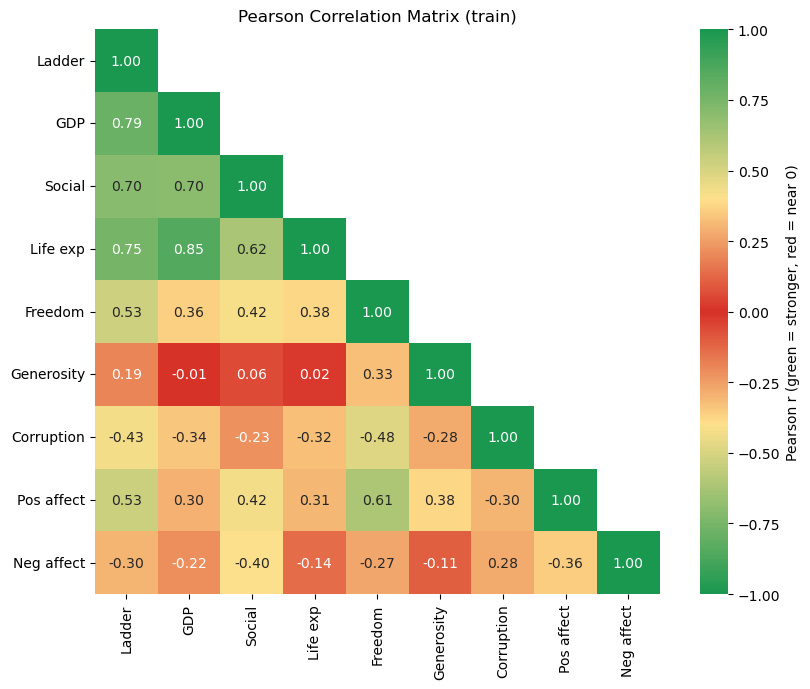

In [8]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

# Strength colormap: red at r = 0, yellow at |r| = 0.4 (moderate threshold), green at |r| = 1
# Positions run 0 to 1 across vmin = -1 to vmax = 1, so |r| = 0.4 sits at 0.3 and 0.7
strength_cmap = LinearSegmentedColormap.from_list('strength', [
	(0.0, '#1a9850'),
	(0.3, '#fee08b'),
	(0.5, '#d73027'),
	(0.7, '#fee08b'),
	(1.0, '#1a9850'),
])

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
	correlation_matrix.rename(index=SHORT_NAMES, columns=SHORT_NAMES),
	mask=mask, annot=True, fmt='.2f', cmap=strength_cmap, vmin=-1, vmax=1, square=True, ax=ax,
	cbar_kws={'label': 'Pearson r (green = stronger, red = near 0)'},
)
ax.set_title('Pearson Correlation Matrix (train)')
plt.tight_layout()
plt.show()

## Ranked Attribute Pairs

Every pair of the 8 attributes (the label excluded), ranked by |r|.

In [9]:
features = correlation_matrix.columns.drop(TARGET)
upper = correlation_matrix.loc[features, features].where(
	np.triu(np.ones((len(features), len(features)), dtype=bool), k=1)
)
pair_corr = (
	upper.stack().rename('Pearson r').rename_axis(['attribute A', 'attribute B']).reset_index()
)
pair_corr['strength'] = pair_corr['Pearson r'].map(pcc_strength)
pair_corr = pair_corr.sort_values('Pearson r', key=abs, ascending=False, ignore_index=True)

print(pair_corr['strength'].value_counts().to_string())
pair_corr.round(3)

strength
weak         15
moderate      7
very weak     5
strong        1


,attribute A,attribute B,Pearson r,strength
0,Log GDP per capita,Healthy life expectancy at birth,0.851,strong
1,Log GDP per capita,Social support,0.697,moderate
2,Social support,Healthy life expectancy at birth,0.621,moderate
3,Freedom to make life choices,Positive affect,0.614,moderate
4,Freedom to make life choices,Perceptions of corruption,-0.481,moderate
5,Social support,Positive affect,0.425,moderate
6,Social support,Freedom to make life choices,0.420,moderate
7,Social support,Negative affect,-0.404,moderate
8,Healthy life expectancy at birth,Freedom to make life choices,0.382,weak
9,Generosity,Positive affect,0.377,weak


- **Strong:** only one pair reaches the strong threshold, Log GDP per capita and Healthy life expectancy at birth (0.851).
- **Moderate:** the next strongest pairs are Log GDP and Social support (0.697), Social support and Healthy life expectancy (0.621), and Freedom and Positive affect (0.614). Freedom and Perceptions of corruption (-0.481) is the strongest negative pair.
- **Very weak:** Generosity has very weak correlations with Log GDP (-0.006) and Healthy life expectancy (0.019).
- Of the 28 attribute pairs, 1 is strong, 7 are moderate, 15 are weak, and 5 are very weak.

## Scatter Matrix

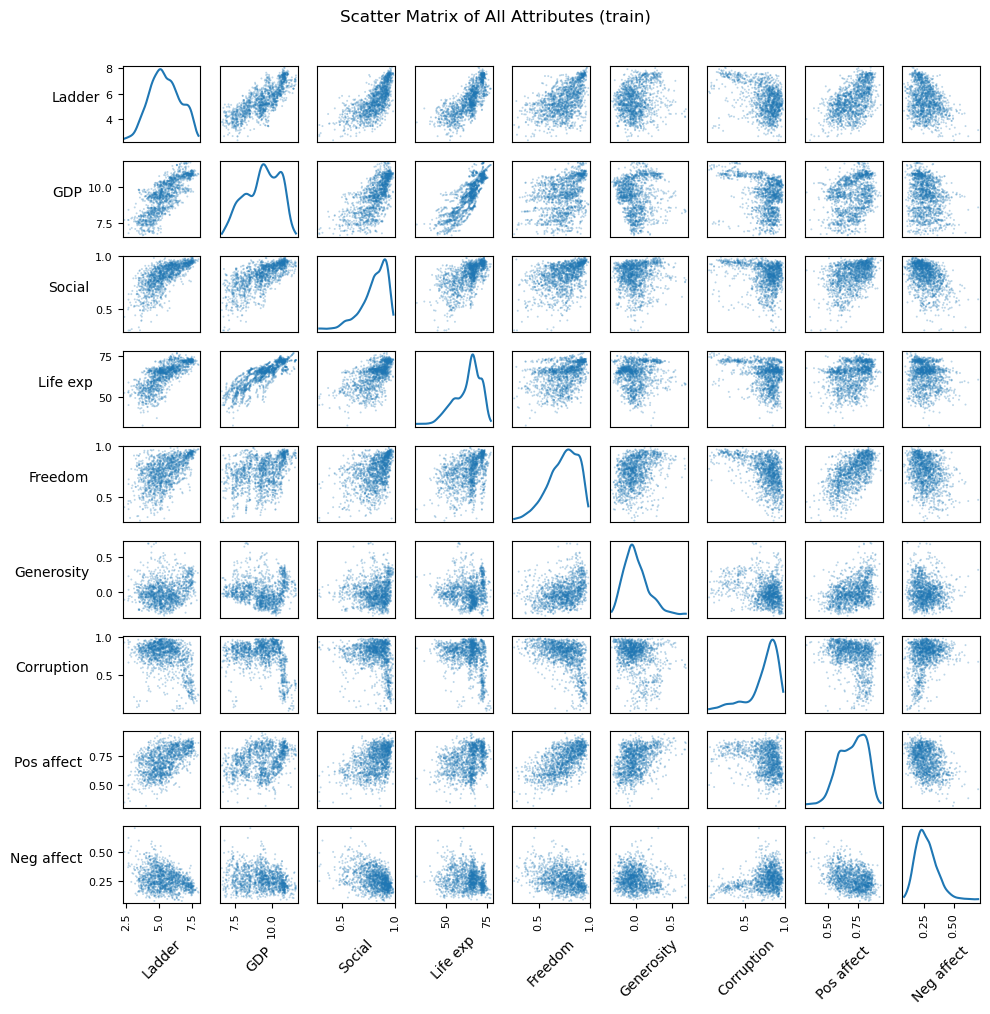

In [10]:
plot_df = train_df.rename(columns=SHORT_NAMES)

axes = scatter_matrix(plot_df, figsize=(10, 10), alpha=0.3, s=8, diagonal='kde')

for ax in axes.flatten():
	ax.xaxis.label.set_rotation(45)
	ax.yaxis.label.set_rotation(0)
	ax.yaxis.label.set_ha('right')

plt.suptitle('Scatter Matrix of All Attributes (train)', y=1.01)
plt.tight_layout()
plt.show()

The scatter matrix shows every attribute pair at once, with each attribute's density on the diagonal.

- Log GDP and Life exp form the tightest band, matching their 0.851 correlation.
- The Corruption row and column show the same two-group shape against Ladder, GDP, and Life exp.
- Generosity shows no clear trend with any attribute.

## Scatter Plots of the Strongest Pairs

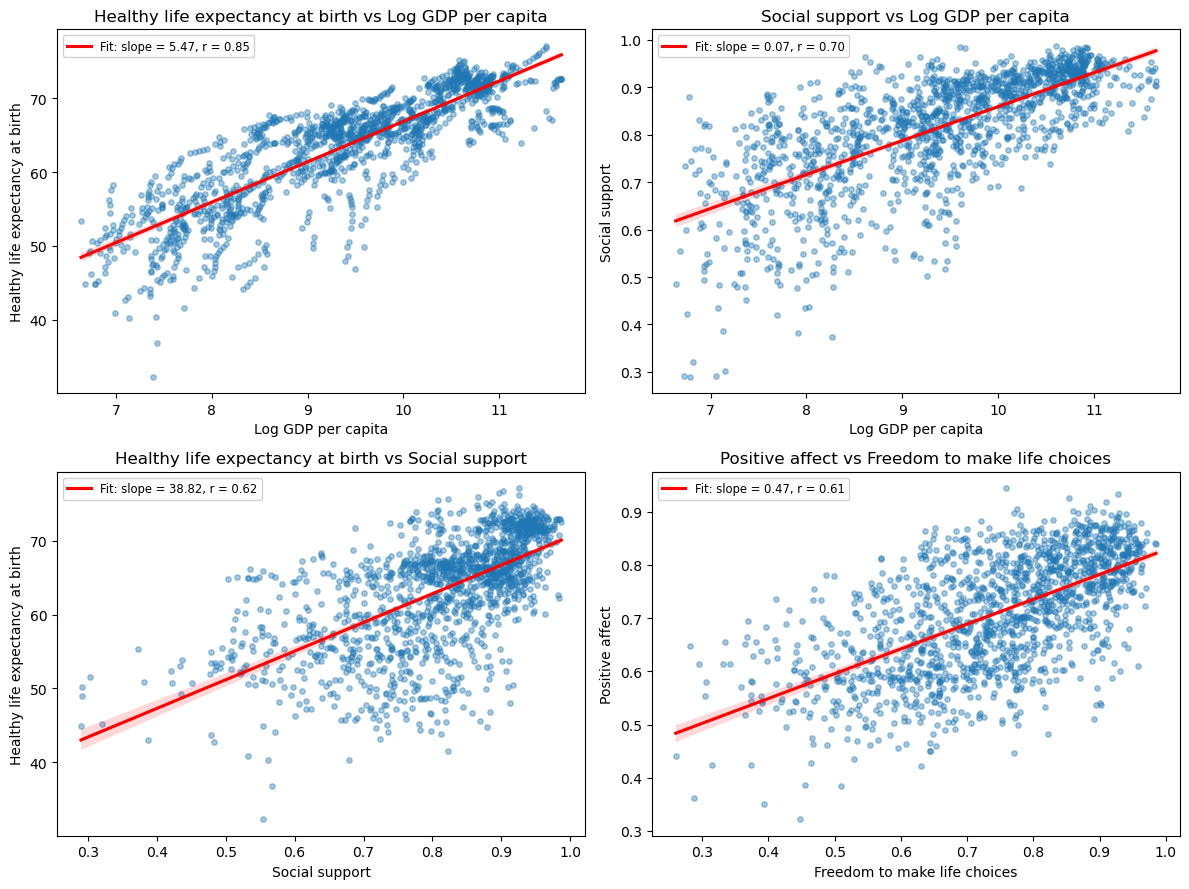

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (_, row) in zip(axes.flatten(), pair_corr.head(4).iterrows()):
	plot_correlation_to_target(df=train_df, feature=row['attribute A'], target=row['attribute B'], ax=ax)

plt.tight_layout()
plt.show()

The four most correlated attribute pairs, each with its fitted line and r.

- **Healthy life expectancy vs Log GDP (r = 0.85):** the points lie in a narrow band along the line, the tightest of the four.
- **Social support vs Log GDP (r = 0.70):** the points rise with Log GDP, but the spread is wider at lower Log GDP values (below about 9) than at higher ones.
- **Healthy life expectancy vs Social support (r = 0.62)** and **Positive affect vs Freedom (r = 0.61):** both rise along the line with a wider spread around it, matching their moderate r.

## Combined Correlation

For every pair of attributes, `combined_corr_to_target` is the multiple correlation R of a linear fit of Life Ladder on both attributes, computed from the three pairwise correlations. `gain_from_combining` is how much R exceeds the stronger single |r|.

In [12]:
pairs_df = rank_feature_pairs_by_combined_corr(df=train_df, target=TARGET)
pairs_df.round(3)

,feature_a,feature_b,feature_a_corr_to_feature_b,best_single_corr_to_target,combined_corr_to_target,gain_from_combining
0,Perceptions of corruption,Positive affect,-0.300,0.535,0.603,0.069
1,Healthy life expectancy at birth,Positive affect,0.312,0.751,0.815,0.064
2,Log GDP per capita,Positive affect,0.296,0.787,0.848,0.061
3,Social support,Healthy life expectancy at birth,0.621,0.751,0.810,0.059
4,Freedom to make life choices,Positive affect,0.614,0.535,0.592,0.058
5,Social support,Perceptions of corruption,-0.226,0.704,0.756,0.052
6,Social support,Positive affect,0.425,0.704,0.750,0.047
7,Social support,Freedom to make life choices,0.420,0.704,0.750,0.046
8,Healthy life expectancy at birth,Freedom to make life choices,0.382,0.751,0.796,0.045
9,Log GDP per capita,Freedom to make life choices,0.360,0.787,0.830,0.043


- The largest gain is 0.069 (Perceptions of corruption + Positive affect), and the highest combined R is 0.848 (Log GDP per capita + Positive affect).

### Log GDP per capita and Healthy life expectancy at birth overlap
- Both have a strong correlation with Life Ladder (0.787 and 0.751), and they are the only strongly correlated attribute pair (0.851).
- Using both together raises the multiple correlation with Life Ladder from 0.787 to 0.802, a gain of only 0.015 (row 21). Adding the second attribute adds little linear information about Life Ladder beyond the first.

---

# Summary

**Attributes vs label (`Life Ladder`)**
- Strong positive: Log GDP per capita (0.787), Healthy life expectancy at birth (0.751), Social support (0.704).
- Moderate: Positive affect (0.535), Freedom to make life choices (0.530), Perceptions of corruption (-0.428).
- Weakest: Negative affect (-0.302), Generosity (0.195).
- Perceptions of corruption's scatter plot shows two groups that a single line does not capture. Its r is -0.428 with all rows and -0.269 without its 130 low outliers.

**Attributes vs attributes**
- One strong pair: Log GDP per capita and Healthy life expectancy at birth (0.851). Combining them adds only 0.015 to the multiple correlation with Life Ladder.
- Strongest moderate pairs: Log GDP and Social support (0.697), Social support and Healthy life expectancy (0.621), Freedom and Positive affect (0.614), Freedom and Perceptions of corruption (-0.481).
- Generosity has very weak correlations with Log GDP (-0.006) and Healthy life expectancy (0.019).